In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import os, shutil, glob, zipfile, re

DRIVE_DIR   = "/content/drive/MyDrive/Corneal_v2"            # <- your upload folder
CSV_NAME    = "Final_Features_MultiLabel_updated.csv"
IMG_NAME    = "Disease_Cell_Images"                           # zip OR folder with this name
LOCAL_DIR   = "/content/data_v2"
IMAGE_DIR   = os.path.join(LOCAL_DIR, "images")
RESULTS_DIR = "/content/drive/MyDrive/CNN_results_v2"         # NEW results folder
os.makedirs(LOCAL_DIR, exist_ok=True); os.makedirs(RESULTS_DIR, exist_ok=True)

CSV_PATH = os.path.join(DRIVE_DIR, CSV_NAME)
assert os.path.exists(CSV_PATH), f"CSV not found: {CSV_PATH}"

if not os.path.isdir(IMAGE_DIR):
    zip_path, folder_path = os.path.join(DRIVE_DIR, IMG_NAME + ".zip"), os.path.join(DRIVE_DIR, IMG_NAME)
    if os.path.exists(zip_path):
        print("Unzipping", zip_path); zipfile.ZipFile(zip_path).extractall(IMAGE_DIR)
    elif os.path.isdir(folder_path):
        print("Copying folder", folder_path); shutil.copytree(folder_path, IMAGE_DIR)
    else:
        raise FileNotFoundError(f"Put {IMG_NAME}.zip or the {IMG_NAME}/ folder inside {DRIVE_DIR}")

IMG_EXT = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")
ALL_IMGS = [p for p in glob.glob(os.path.join(IMAGE_DIR, "**", "*"), recursive=True)
            if p.lower().endswith(IMG_EXT) and "__MACOSX" not in p]
print("Images found (all sub-folders):", len(ALL_IMGS))
print("Example file names:", [os.path.relpath(p, IMAGE_DIR) for p in ALL_IMGS[:8]])

Unzipping /content/drive/MyDrive/Corneal_v2/Disease_Cell_Images.zip
Images found (all sub-folders): 1543
Example file names: ['Disease_Cell_Images/NEB-2025-10-17598 L_SP.jpg', 'Disease_Cell_Images/NEB- 2025 -10- 17603 R_SP.jpg', 'Disease_Cell_Images/NEB-23024-02-15801 R_SP.jpg', 'Disease_Cell_Images/NEB-2023-09-15370 R_SP.jpg', 'Disease_Cell_Images/NEB-2025-09-17519 R_SP.jpg', 'Disease_Cell_Images/NEB-2020-11-12834 L_SP.jpg', 'Disease_Cell_Images/NEB-2022-03-13777 L_SP.jpg', 'Disease_Cell_Images/NEB-2023-11-15576 R_SP.jpg']


 Match CSV rows to images

In [3]:
import pandas as pd
df = pd.read_csv(CSV_PATH)
print("CSV rows:", len(df))

def norm(s): return re.sub(r"[^a-z0-9]", "", str(s).lower())
def short_key(s):
    m = re.search(r"(\d{4,6})[\s_\-]*([LR])(?![A-Z])", str(s).upper())
    return f"{m.group(1)}{m.group(2)}" if m else None

full_map, short_map, dup = {}, {}, []
for p in ALL_IMGS:
    stem = os.path.splitext(os.path.basename(p))[0]
    k = norm(stem)
    if k in full_map: dup.append(stem)
    full_map.setdefault(k, p)
    sk = short_key(stem)
    if sk: short_map.setdefault(sk, []).append(p)

# pass 1: exact (normalised) name match
df["Img_Path"] = df["Tissue_ID"].map(lambda t: full_map.get(norm(t)))
# pass 2: tissue-number + eye fallback, only for images not already taken and only if unambiguous
taken = set(df["Img_Path"].dropna())
sk_rows = df[df["Img_Path"].isna()]["Tissue_ID"].map(short_key)
for i, k in sk_rows.items():
    cands = [p for p in short_map.get(k or "", []) if p not in taken]
    if len(cands) == 1 and (sk_rows == k).sum() == 1:
        df.at[i, "Img_Path"] = cands[0]; taken.add(cands[0])
unmatched = df[df["Img_Path"].isna()]
print(f"Matched: {df['Img_Path'].notna().sum()} / {len(df)}   | unmatched rows: {len(unmatched)}")
if dup: print("WARNING duplicate image names (first kept):", dup[:5])
if len(unmatched):
    print("Unmatched Tissue_IDs (first 15):", unmatched["Tissue_ID"].head(15).tolist())
used = set(df["Img_Path"].dropna())
print("Images not used by any CSV row:", len(set(ALL_IMGS) - used))
n_dup = df["Img_Path"].dropna().duplicated().sum()
print("Image used by >1 row:", n_dup)
assert n_dup == 0, "Two rows point to the same image - check file names"

# Stop if matching is clearly wrong
assert df["Img_Path"].notna().mean() > 0.9, "Less than 90% of rows matched an image - fix img matching before training!"
df = df[df["Img_Path"].notna()].reset_index(drop=True)
unmatched.to_csv(os.path.join(RESULTS_DIR, "unmatched_rows.csv"), index=False)

CSV rows: 1548
Matched: 1527 / 1548   | unmatched rows: 21
WARNING duplicate image names (first kept): ['NEB-2021-11-13399 R_SP', 'NEB-2026-03-18084L_SP']
Unmatched Tissue_IDs (first 15): ['NEB-2020-09-12672 R', 'NEB-2020-09-12683 L', 'NEB-2020-10-12726 R', 'NEB-2020-10-12733 L', 'NEB-2022-10-14315 L', 'NEB-2022-10-14349 L', 'NEB-2023-02-14710 R', 'NEB-2023-04-14996 R', 'NEB-2023-08-15300 R', 'NEB-2024-06-16116 L', 'NEB-2024-06-16117 R', 'NEB-2024-06-16130 L', 'NEB-2024-08-16256 L', 'NEB-2024-08-16296 L', 'NEB-2025-09-17506 R']
Images not used by any CSV row: 16
Image used by >1 row: 0


Libraries

In [4]:
import json, math
import numpy as np
import matplotlib.pyplot as plt
import cv2
import torch
import torch.nn as nn
import torchvision
from torchvision import models
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

device: cpu


Defines the image dimensions, five disease labels, six numerical features, and paths to the saved disease and severity models.

In [5]:
APPLY_CLAHE = False                          # see the note at the top: True only if training images were CLAHE-processed
IMG_W, IMG_H = 384, 288                      # model input size (same as training)
PREP_W, PREP_H = 512, 384                    # preparation size used with CLAHE (notebook 03)
DIS_COLS = ["FECD", "Guttata", "Folds", "PolyPleo", "LowCD"]
FEATURES = ["ECD_CD_cells_per_mm2", "ECD_Deficit", "SD", "CV", "HEX_percent", "Donor_Age"]
HEAD_NAME = {"FECDgroup": "FECD group", "Folds": "Folds", "Guttata": "Guttata"}

SEV_DIR = os.path.join(RESULTS_DIR, "severity_densenet121")
CMB_DIR = os.path.join(RESULTS_DIR, "combined_final"); os.makedirs(CMB_DIR, exist_ok=True)

# disease model: full comparison notebook (preferred) or fusion-only notebook
if os.path.exists(os.path.join(RESULTS_DIR, "final_densenet121", "Image_plus_numbers.pt")):
    DIS_DIR = os.path.join(RESULTS_DIR, "final_densenet121")
    DIS_WEIGHTS = os.path.join(DIS_DIR, "Image_plus_numbers.pt")
    DIS_THR = json.load(open(os.path.join(DIS_DIR, "summary_final.json")))["thresholds"]["Image + numbers"]
    DIS_PRED_FILE = os.path.join(DIS_DIR, "test_predictions_all.csv")
else:
    DIS_DIR = os.path.join(RESULTS_DIR, "final_fusion_densenet121")
    DIS_WEIGHTS = os.path.join(DIS_DIR, "Fusion_densenet121.pt")
    DIS_THR = json.load(open(os.path.join(DIS_DIR, "summary_fusion.json")))["thresholds"]
    DIS_PRED_FILE = os.path.join(DIS_DIR, "test_predictions_fusion.csv")
assert os.path.exists(DIS_WEIGHTS), "Disease model not found - run Fusion_DenseNet121_Retrain_v2 first"

sev_sum = json.load(open(os.path.join(SEV_DIR, "summary_severity.json")))
SEV_HEADS = sev_sum["severity_heads"]; SEV_COLS = list(SEV_HEADS)
cmb_path = os.path.join(CMB_DIR, "combined_summary.json")
cmb = json.load(open(cmb_path)) if os.path.exists(cmb_path) else {}
SEV_THR = {h: cmb.get("severity_thresholds", {}).get(h, sev_sum["severity_thresholds"][h]) for h in SEV_COLS}
FECD_SEV_METHOD = cmb.get("fecd_sev_method", "model")

# number scaling rebuilt from the SAME training rows used in training (rows saved in cv_folds.csv)
folds = pd.read_csv(os.path.join(RESULTS_DIR, "cv_folds.csv"))
man = df.merge(folds, on="Tissue_ID", how="inner")          # df = matched rows from Step 3
train_df = man[man["Split"] == "train"]
_imp = SimpleImputer(strategy="median").fit(train_df[FEATURES])
_sc = StandardScaler().fit(_imp.transform(train_df[FEATURES]))
scale_tab = lambda f: _sc.transform(_imp.transform(f[FEATURES])).astype(np.float32)

# image-quality focus rule: old notebook-03 config if present, else 5th percentile of training-image focus
old_cfg = "/content/drive/MyDrive/Processed_SP_ML/image_config.json"
if os.path.exists(old_cfg):
    FOCUS_LOW = float(json.load(open(old_cfg))["quality_rules"]["low"].split("Q_Focus < ")[1].split()[0])
else:
    foc = [cv2.Laplacian(cv2.resize(cv2.imread(p, 0), (640, 480), interpolation=cv2.INTER_AREA), cv2.CV_64F).var()
           for p in train_df["Img_Path"].sample(min(300, len(train_df)), random_state=0)]
    FOCUS_LOW = float(np.percentile(foc, 5))
print("Disease model    :", DIS_WEIGHTS)
print("Disease cut-offs :", {k: round(v, 3) for k, v in DIS_THR.items()})
print("Severity outputs :", SEV_COLS)
print("Severity cut-offs:", {k: round(v, 3) for k, v in SEV_THR.items()}, "| FECD severity method:", FECD_SEV_METHOD)
print(f"Scaler fitted on {len(train_df)} training rows | focus 'low quality' limit: {FOCUS_LOW:.1f} | APPLY_CLAHE = {APPLY_CLAHE}")

Disease model    : /content/drive/MyDrive/CNN_results_v2/final_densenet121/Image_plus_numbers.pt
Disease cut-offs : {'FECD': 0.235, 'Guttata': 0.442, 'Folds': 0.487, 'PolyPleo': 0.44, 'LowCD': 0.466}
Severity outputs : ['FECDgroup', 'Folds', 'Guttata']
Severity cut-offs: {'FECDgroup': 0.57, 'Folds': 0.491, 'Guttata': 0.434} | FECD severity method: model
Scaler fitted on 1222 training rows | focus 'low quality' limit: 23.1 | APPLY_CLAHE = False


Defines the DenseNet121-based disease and multi-task severity architectures, then loads their saved weights.

In [6]:
def densenet():
    m = models.densenet121(weights=None); dim = m.classifier.in_features; m.classifier = nn.Identity()
    return m, dim

class Fusion(nn.Module):                     # disease model
    def __init__(self):
        super().__init__()
        self.backbone, dim = densenet(); self.cam_layer = self.backbone.features
        self.tab_mlp = nn.Sequential(nn.Linear(len(FEATURES), 32), nn.ReLU(), nn.Dropout(0.2), nn.Linear(32, 32), nn.ReLU())
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(dim + 32, 128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, len(DIS_COLS)))
    def forward(self, x, tab):
        return self.head(torch.cat([self.backbone(x), self.tab_mlp(tab)], 1))

class FusionMultiTask(nn.Module):            # severity model
    def __init__(self):
        super().__init__()
        self.backbone, dim = densenet(); self.cam_layer = self.backbone.features
        self.tab_mlp = nn.Sequential(nn.Linear(len(FEATURES), 32), nn.ReLU(), nn.Dropout(0.2), nn.Linear(32, 32), nn.ReLU())
        self.shared = nn.Sequential(nn.Dropout(0.3), nn.Linear(dim + 32, 128), nn.ReLU(), nn.Dropout(0.3))
        self.disease_head = nn.Linear(128, len(DIS_COLS))
        self.severity_head = nn.Linear(128, len(SEV_COLS))
    def forward(self, x, tab):
        z = self.shared(torch.cat([self.backbone(x), self.tab_mlp(tab)], 1))
        return self.disease_head(z), self.severity_head(z)

dis_model = Fusion().to(DEVICE)
dis_model.load_state_dict(torch.load(DIS_WEIGHTS, map_location=DEVICE)); dis_model.eval()
sev_model = FusionMultiTask().to(DEVICE)
sev_model.load_state_dict(torch.load(os.path.join(SEV_DIR, "final_multitask.pt"), map_location=DEVICE)); sev_model.eval()
print(f"OK - disease model and severity model ({len(SEV_COLS)} severity outputs) loaded")

OK - disease model and severity model (3 severity outputs) loaded


Defines image preprocessing, resizing, and image-quality checks based on contrast, focus, darkness, and saturation.

In [7]:
CLAHE = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
T = torchvision.transforms
TF_EVAL = T.Compose([T.ToPILImage(), T.Resize((IMG_H, IMG_W)), T.Grayscale(3), T.ToTensor(),
                     T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def check_quality(gray):
    g = cv2.resize(gray, (640, 480), interpolation=cv2.INTER_AREA)
    q = {"std": g.std(), "focus": cv2.Laplacian(g, cv2.CV_64F).var(), "dark": (g < 20).mean(), "saturated": (g > 245).mean()}
    if q["std"] < 5 or q["saturated"] > 0.5: return "Unusable", q
    if q["focus"] < FOCUS_LOW or q["dark"] > 0.45: return "Low", q
    return "OK", q

def prepare_raw(path):
    """New microscope image -> prepared exactly like the training images."""
    raw = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if raw is None: raise ValueError(f"Cannot read image: {path}")
    quality, q = check_quality(raw)
    prepared = CLAHE.apply(cv2.resize(raw, (PREP_W, PREP_H), interpolation=cv2.INTER_AREA)) if APPLY_CLAHE else raw
    return prepared, quality

def make_tab(ecd, sd, cv, hex_pct, age):
    row = pd.DataFrame([{"ECD_CD_cells_per_mm2": ecd, "ECD_Deficit": None if ecd is None else max(0, 2500 - ecd),
                         "SD": sd, "CV": cv, "HEX_percent": hex_pct, "Donor_Age": age}], dtype=float)
    return torch.tensor(scale_tab(row)), row
print("OK - preparation functions ready")

OK - preparation functions ready


Defines the inference pipeline, including disease prediction, severity prediction, and Grad-CAM explanations.

In [8]:
ORD = {"None": 0, "Mild": 1, "Mod/Sev": 2}

@torch.no_grad()
def run_models(prepared, tab):
    x = TF_EVAL(prepared).unsqueeze(0).to(DEVICE); t = tab.to(DEVICE); xf = torch.flip(x, dims=[3])
    with torch.autocast("cuda", enabled=DEVICE == "cuda"):
        pd_ = (torch.sigmoid(dis_model(x, t)) + torch.sigmoid(dis_model(xf, t))) / 2
        s1, s2 = sev_model(x, t)[1], sev_model(xf, t)[1]
        ps = (torch.sigmoid(s1) + torch.sigmoid(s2)) / 2
    return pd_.float().cpu().numpy()[0], ps.float().cpu().numpy()[0], x

def gradcam(x, tab, j):
    acts, grads = {}, {}
    def hook(m, i, o):
        acts["a"] = o; o.register_hook(lambda g: grads.__setitem__("g", g))
    h = dis_model.cam_layer.register_forward_hook(hook)
    with torch.enable_grad():
        dis_model.zero_grad(); dis_model(x, tab.to(DEVICE))[0, j].backward()
    h.remove()
    w = grads["g"].mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((w * acts["a"]).sum(1)).squeeze().detach().float().cpu().numpy()
    cam = cv2.resize(cam, (IMG_W, IMG_H)); return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

def analyse(prepared, ecd, sd, cv, hex_pct, age, name="New cornea", quality="OK", show=True):
    tab, row = make_tab(ecd, sd, cv, hex_pct, age)
    P, PS, x = run_models(prepared, tab)
    found = [c for j, c in enumerate(DIS_COLS) if P[j] >= DIS_THR[c]]
    sevs = []
    for k, (h, ds) in enumerate(SEV_HEADS.items()):
        if not any(c in found for c in ds): continue
        if h == "FECDgroup" and FECD_SEV_METHOD == "cd_rule":
            mod = ecd is not None and ecd < 1600
        else:
            mod = PS[k] >= SEV_THR[h]
        sevs.append((HEAD_NAME.get(h, h), "Mod/Sev" if mod else "Mild"))
    if "Guttata" in found and "Guttata" not in SEV_HEADS:
        sevs.append(("Guttata", "Mild (not gradable)"))
    overall = max([s.split()[0] for _, s in sevs], key=lambda s: ORD[s]) if sevs else "None"
    rep = {"Cornea": name, "Image quality": quality,
           "Diseases found": ", ".join(f"{c} ({P[DIS_COLS.index(c)]:.2f})" for c in found) or "None (Normal)",
           "Not found": ", ".join(f"{c} ({P[j]:.2f})" for j, c in enumerate(DIS_COLS) if c not in found) or "-",
           "Severity": ", ".join(f"{d}: {s}" for d, s in sevs) or "-", "Overall severity": overall}
    if show:
        print("=" * 70)
        for k, v in rep.items(): print(f"{k:<17}: {v}")
        if quality != "OK": print("WARNING: image quality is", quality, "- treat this result with caution / re-image")
        print("=" * 70)
        n = 1 + len(found)
        fig, ax = plt.subplots(1, n, figsize=(4.2 * n, 3.4))
        ax = np.atleast_1d(ax); disp = cv2.resize(prepared, (IMG_W, IMG_H))
        ax[0].imshow(disp, cmap="gray"); ax[0].set_title(f"{name}\n(input image)", fontsize=9)
        for k, c in enumerate(found, 1):
            ax[k].imshow(disp, cmap="gray"); ax[k].imshow(gradcam(x, tab, DIS_COLS.index(c)), cmap="jet", alpha=0.4)
            ax[k].set_title(f"Grad-CAM: {c} (P={P[DIS_COLS.index(c)]:.2f})", fontsize=9)
        for a in ax: a.axis("off")
        plt.tight_layout(); plt.show()
    rep.update({f"P_{c}": float(P[j]) for j, c in enumerate(DIS_COLS)})
    rep.update({f"PSev_{h}": float(PS[k]) for k, h in enumerate(SEV_COLS)})
    return rep

def analyse_from_dataset(tissue_id, show=True):
    r = man.loc[man["Tissue_ID"] == tissue_id].iloc[0]
    img = cv2.imread(r["Img_Path"], cv2.IMREAD_GRAYSCALE)                  # used exactly as in training
    g = lambda c: None if pd.isna(r[c]) else float(r[c])
    rep = analyse(img, g("ECD_CD_cells_per_mm2"), g("SD"), g("CV"), g("HEX_percent"), g("Donor_Age"),
                  name=tissue_id, quality=check_quality(img)[0], show=show)
    if show: print("True label (clinician / dataset):", r["Combination"])
    return rep
print("OK - analyse() ready")

OK - analyse() ready


Checks whether this notebook reproduces the previously evaluated disease and severity predictions on selected test records.

In [9]:
saved_d = pd.read_csv(DIS_PRED_FILE)
saved_s = pd.read_csv(os.path.join(SEV_DIR, "test_predictions_severity.csv"))
ids = saved_d["Tissue_ID"].sample(min(10, len(saved_d)), random_state=0).tolist()
rows = []
for tid in ids:
    rep = analyse_from_dataset(tid, show=False)
    d, s = saved_d.set_index("Tissue_ID").loc[tid], saved_s.set_index("Tissue_ID").loc[tid]
    rows.append({"Tissue_ID": tid,
                 "max diff disease prob": max(abs(rep[f"P_{c}"] - d[f"P_Fus_{c}"]) for c in DIS_COLS),
                 "max diff severity prob": max(abs(rep[f"PSev_{h}"] - s[f"PSev_{h}"]) for h in SEV_COLS)})
chk = pd.DataFrame(rows); display(chk.round(4))
ok = chk[["max diff disease prob", "max diff severity prob"]].max().max() < 0.01
print("PASS - notebook reproduces the evaluated models" if ok else "CHECK - differences above 0.01, tell Claude")

,Tissue_ID,max diff disease prob,max diff severity prob
0,NEB-2023-03-14830 R,0.0009,0.0016
1,NEB-2023-02-14764 R,0.0031,0.0004
2,NEB-2023-03-14827 R,0.0019,0.0008
3,NEB-2023-11-15591 R,0.0009,0.0004
4,NEB-2023-05-15063 L,0.0012,0.0007
5,NEB-2023-10-15462 R,0.0007,0.0008
6,NEB-2021-01-12939 R,0.0005,0.0005
7,NEB-2023-02-14796 R,0.0011,0.0006
8,NEB-2023-09-15405 R,0.0035,0.0013
9,NEB-2025-11-17630 L,0.0002,0.0014


PASS - notebook reproduces the evaluated models


Demonstrate predictions on an existing cornea

Some test corneas you can try: ['NEB-2020-04-12255 L', 'NEB-2025-10-17594 L', 'NEB-2022-06-13962 R', 'NEB-2025-09-17516 L', 'NEB-2020-01-11908 R']
Cornea           : NEB-2020-04-12255 L
Image quality    : OK
Diseases found   : FECD (0.64), Folds (0.73), PolyPleo (0.79), LowCD (0.94)
Not found        : Guttata (0.17)
Severity         : FECD group: Mod/Sev, Folds: Mod/Sev
Overall severity : Mod/Sev


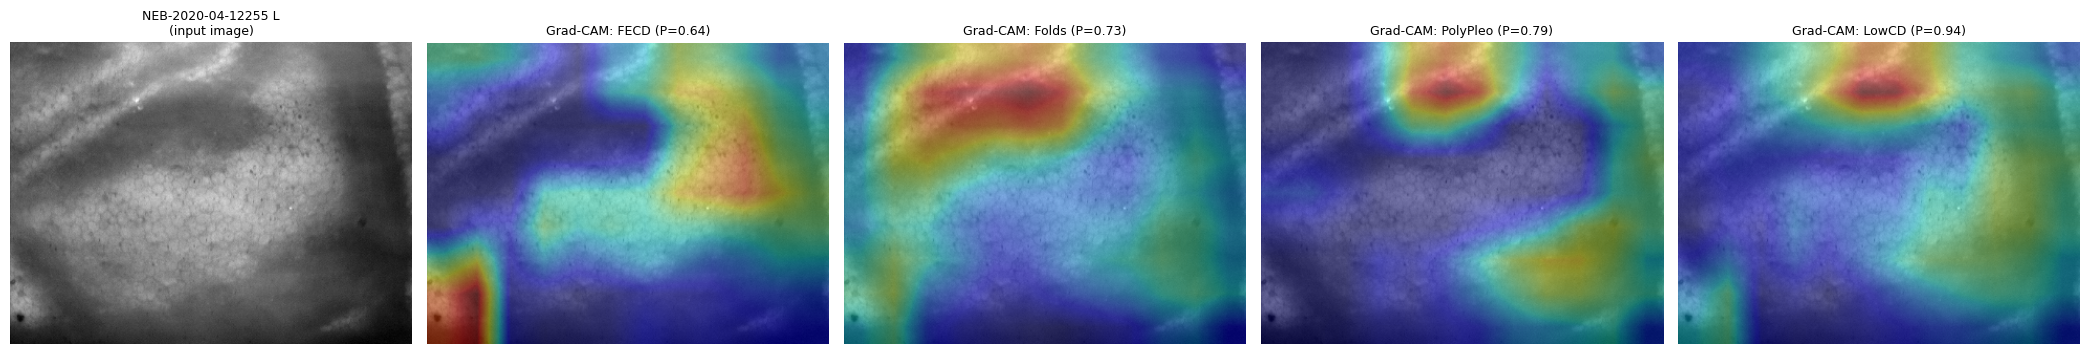

True label (clinician / dataset): Folds + LowCD


In [10]:
test_ids = man.loc[man["Split"] == "test", "Tissue_ID"]
print("Some test corneas you can try:", test_ids.sample(5, random_state=1).tolist())
analyse_from_dataset(test_ids.sample(1, random_state=1).iloc[0]);

Creates or loads image-feature representations from the training images. It measures how unusual a new image is compared with the training images and establishes warning and rejection thresholds using the test-set distance distribution.

Reference: 1222 training images | unseen test distances: median 0.129, 95th 0.170 (warn), 99th 0.188 (reject)


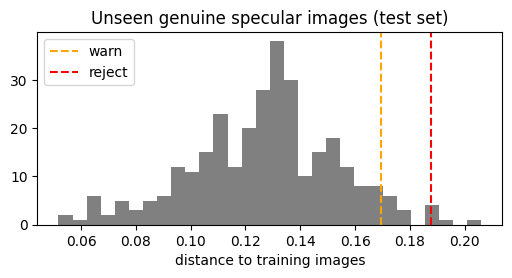

In [11]:
REF_PATH = os.path.join(CMB_DIR, "ood_reference_v2.npz")

@torch.no_grad()
def embed(prepared):
    x = TF_EVAL(prepared).unsqueeze(0).to(DEVICE)
    f = dis_model.backbone(x).float()
    return torch.nn.functional.normalize(f, dim=1).cpu().numpy()[0]

def knn_distance(e, ref, k=5):
    sims = ref @ e
    return float(1 - np.sort(sims)[-k:].mean())          # 0 = identical to training images, larger = more unusual

if os.path.exists(REF_PATH):
    z = np.load(REF_PATH); REF, d_test = z["ref"], z["d_test"]
else:
    load = lambda p: cv2.imread(p, cv2.IMREAD_GRAYSCALE)
    REF = np.stack([embed(load(p)) for p in man.loc[man["Split"] == "train", "Img_Path"]])
    d_test = np.array([knn_distance(embed(load(p)), REF) for p in man.loc[man["Split"] == "test", "Img_Path"]])
    np.savez(REF_PATH, ref=REF, d_test=d_test)
OOD_WARN, OOD_REJECT = np.percentile(d_test, 95), np.percentile(d_test, 99)
print(f"Reference: {len(REF)} training images | unseen test distances: median {np.median(d_test):.3f}, "
      f"95th {OOD_WARN:.3f} (warn), 99th {OOD_REJECT:.3f} (reject)")
plt.figure(figsize=(6, 2.5)); plt.hist(d_test, bins=30, color="grey")
plt.axvline(OOD_WARN, color="orange", ls="--", label="warn"); plt.axvline(OOD_REJECT, color="red", ls="--", label="reject")
plt.xlabel("distance to training images"); plt.title("Unseen genuine specular images (test set)"); plt.legend(); plt.show()

Checks whether the numerical biomarkers fall within physically plausible ranges and whether they are within the ranges observed during training. It also checks consistency between measurements and flags missing or invalid values.

In [12]:
LIMITS = {"ecd": (300, 4500), "sd": (40, 1000), "cv": (10, 110), "hex_pct": (5, 100), "age": (1, 110)}   # physically possible
_col = {"ecd": "ECD_CD_cells_per_mm2", "cv": "CV", "hex_pct": "HEX_percent", "age": "Donor_Age"}
TRAIN_RANGE = {k: (float(train_df[c].min()), float(train_df[c].max())) for k, c in _col.items()}          # seen in training
NAMES = {"ecd": "ECD", "sd": "SD", "cv": "CV", "hex_pct": "HEX %", "age": "Donor age"}
MIN_SIDE = 300                                                                                          # Konan images are 640x480
print("Training ranges:", {NAMES[k]: v for k, v in TRAIN_RANGE.items()})

def validate_numbers(ecd, sd, cv, hex_pct, age):
    errors, warnings, clean = [], [], {}
    for k, val in dict(ecd=ecd, sd=sd, cv=cv, hex_pct=hex_pct, age=age).items():
        if val is None or (isinstance(val, float) and math.isnan(val)):
            warnings.append(f"{NAMES[k]} missing - filled with the training median"); clean[k] = None; continue
        try:
            val = float(val)
        except (TypeError, ValueError):
            errors.append(f"{NAMES[k]} = {val!r} is not a number"); clean[k] = None; continue
        clean[k] = val
        lo, hi = LIMITS[k]
        if val <= 0:
            errors.append(f"{NAMES[k]} = {val:g} - zero or negative is impossible; use None if unknown")
        elif not lo <= val <= hi:
            errors.append(f"{NAMES[k]} = {val:g} is outside the possible range {lo}-{hi}")
        elif k in TRAIN_RANGE and not TRAIN_RANGE[k][0] <= val <= TRAIN_RANGE[k][1]:
            warnings.append(f"{NAMES[k]} = {val:g} is outside the range seen in training {TRAIN_RANGE[k]}")
    e, s, c = clean["ecd"], clean["sd"], clean["cv"]
    if not errors and None not in (e, s, c):
        expected_sd = c / 100 * 1e6 / e                       # CellChek: SD = CV x mean cell area (within 1% in the v2 data)
        if abs(s / expected_sd - 1) > 0.05:
            errors.append(f"SD {s:g} does not match ECD and CV (expected about {expected_sd:.0f}) - check for a typing mistake")
    if sum(v is None for v in clean.values()) >= 3:
        errors.append("Too many CellChek numbers missing - the model needs them")
    return errors, warnings

def validate_image(path):
    errors, warnings = [], []
    col = cv2.imread(path, cv2.IMREAD_COLOR)
    if col is None: return ["File is not a readable image"], [], None, None
    c = col.astype(np.float32)
    colour = np.abs(c[..., 0] - c[..., 1]).mean() + np.abs(c[..., 1] - c[..., 2]).mean()
    if colour > 3: errors.append(f"Colour image (colour score {colour:.1f}) - specular microscopy images are greyscale")
    h, w = col.shape[:2]
    if min(h, w) < MIN_SIDE:
        errors.append(f"Resolution too low ({w}x{h}; Konan images are 640x480). Enlarging it makes cells look bigger, "
                      f"which would falsely suggest LOW cell density / FECD")
    if not 1.1 <= w / h <= 1.6: warnings.append(f"Unusual shape {w}x{h} (Konan images are 4:3) - may be a screenshot or crop")
    prepared, quality = prepare_raw(path)
    if quality == "Unusable": errors.append("Image quality unusable (blank / saturated)")
    elif quality == "Low": warnings.append("Low image quality (blurred or dark)")
    d = knn_distance(embed(prepared), REF)
    if d > OOD_REJECT: errors.append(f"Does not look like the training specular images (distance {d:.3f} > {OOD_REJECT:.3f})")
    elif d > OOD_WARN: warnings.append(f"Image is unusual compared with training images (distance {d:.3f})")
    return errors, warnings, prepared, quality

# SELF-TEST - you should see REJECTED for the first, third, fourth and fifth lines
for args in [(0, 0, 0, 0, 0), (2650, 143, 38, 55, 65), (2650, 120, 38, 55, 65), (None, None, None, 55, 65), (-5, 143, 38, 55, 65)]:
    e, w = validate_numbers(*args)
    print(f"{str(args):<32} ->", "REJECTED: " + e[0] if e else "OK" + (f" (warning: {w[0]})" if w else ""))

Training ranges: {'ECD': (676.0, 4484.0), 'CV': (19.0, 100.0), 'HEX %': (15.0, 76.0), 'Donor age': (15.0, 79.0)}
(0, 0, 0, 0, 0)                  -> REJECTED: ECD = 0 - zero or negative is impossible; use None if unknown
(2650, 143, 38, 55, 65)          -> OK
(2650, 120, 38, 55, 65)          -> REJECTED: SD 120 does not match ECD and CV (expected about 143) - check for a typing mistake
(None, None, None, 55, 65)       -> REJECTED: Too many CellChek numbers missing - the model needs them
(-5, 143, 38, 55, 65)            -> REJECTED: ECD = -5 - zero or negative is impossible; use None if unknown


Validates both the image and numerical measurements before running inference. If the inputs fail validation, it normally stops rather than producing a potentially unreliable report; force=True allows the user to override this safeguard.

In [13]:
def safe_analyse(path, ecd, sd, cv, hex_pct, age, name=None, force=False):
    name = name or os.path.splitext(os.path.basename(path))[0]
    ie, iw, prepared, quality = validate_image(path)
    ne, nw = validate_numbers(ecd, sd, cv, hex_pct, age)
    errors, warnings = ie + ne, iw + nw
    print("=" * 70); print(f"INPUT CHECK - {name}")
    for e in errors: print("  REJECTED:", e)
    for w in warnings: print("  WARNING :", w)
    if not errors and not warnings: print("  All input checks passed")
    if errors and not force:
        print("RESULT NOT PRODUCED - fix the inputs above (or use force=True only if you are sure)"); print("=" * 70)
        return None
    if errors: print("  force=True used - result produced despite failed checks, NOT reliable")
    return analyse(prepared, ecd, sd, cv, hex_pct, age, name=name, quality=quality)
print("OK - safe_analyse() ready: use this instead of analyse() for new corneas")

OK - safe_analyse() ready: use this instead of analyse() for new corneas


Applies the image and numerical-input checks to the genuine test records. It reports the percentage of cases accepted by the image check, the numerical check, and both checks together.

In [14]:
res = []
for _, r in man[man["Split"] == "test"].iterrows():
    img = cv2.imread(r["Img_Path"], cv2.IMREAD_GRAYSCALE)
    d = knn_distance(embed(img), REF)
    g = lambda c: None if pd.isna(r[c]) else float(r[c])
    ne, _ = validate_numbers(g("ECD_CD_cells_per_mm2"), g("SD"), g("CV"), g("HEX_percent"), g("Donor_Age"))
    res.append({"image_ok": d <= OOD_REJECT, "numbers_ok": len(ne) == 0})
res = pd.DataFrame(res)
print(f"Genuine test corneas - image accepted: {res['image_ok'].mean():.1%} | numbers accepted: {res['numbers_ok'].mean():.1%} "
      f"| both: {(res['image_ok'] & res['numbers_ok']).mean():.1%}")

Genuine test corneas - image accepted: 98.7% | numbers accepted: 98.0% | both: 96.7%


Allows the user to upload a new corneal image and enter its CellChek measurements. The safe_analyse() function then checks the inputs and, if acceptable, generates the disease and severity report.

In [23]:
from google.colab import files
up = files.upload()                                  # choose the specular microscopy image
img_path = list(up.keys())[0]
safe_analyse(img_path, ecd=2650, sd=143, cv=38, hex_pct=55, age=65);   # <<< type the CellChek values here

Saving west-virginia-gray-cottage-64dd6bb056057.avif to west-virginia-gray-cottage-64dd6bb056057.avif
INPUT CHECK - west-virginia-gray-cottage-64dd6bb056057
  REJECTED: Colour image (colour score 52.3) - specular microscopy images are greyscale
RESULT NOT PRODUCED - fix the inputs above (or use force=True only if you are sure)
